## Data

In [ ]:
import sys
from pathlib import Path


# Add the repo root (the folder containing src/) to sys.path
ROOT = Path.cwd()
while not (ROOT / "src" / "common.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.common import PERIODS, load_tcode

PERIOD = "1975-1989"
START, END = PERIODS[PERIOD]
TRAIN_START = "1960-01-01"

df = load_tcode()
desc  = df.loc[START:END]
train = df.loc[TRAIN_START:END]

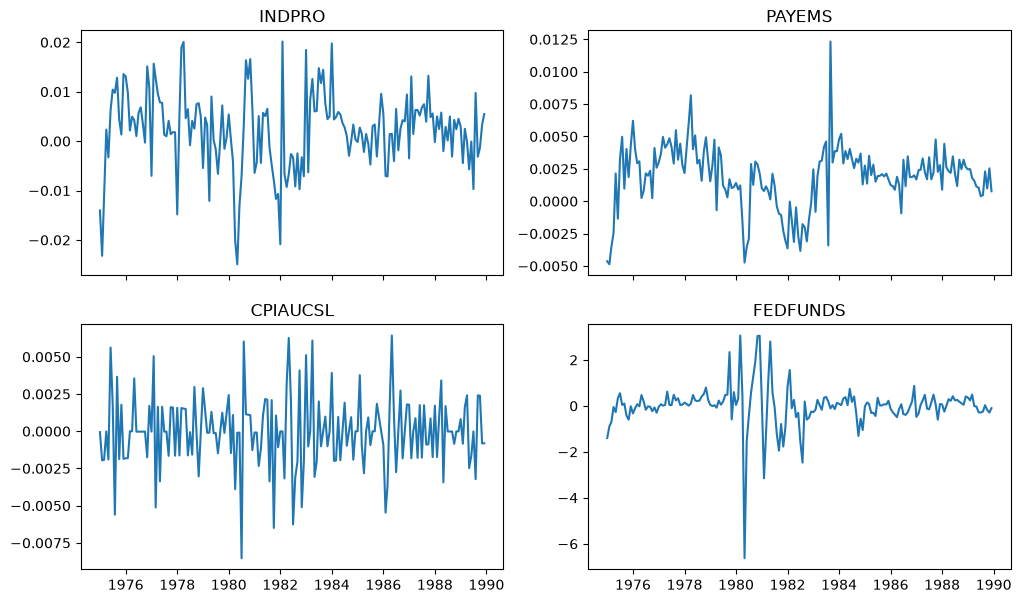

In [6]:
import matplotlib.pyplot as plt 
import seaborn as sns

fig, axes = plt.subplots(2,2, figsize=(12, 7), sharex=True)

for ax, col in zip(axes.flat, ["INDPRO", "PAYEMS", "CPIAUCSL", "FEDFUNDS"]):
    ax.plot(desc.index, desc[col])
    ax.set_title(col)


- All four series are visibly more volatile before 1984. Std pre vs post 1984:
  INDPRO 0.94% → 0.49%, PAYEMS 0.30% → 0.11%, CPIAUCSL 0.26% → 0.20%, FEDFUNDS 1.14 → 0.36 pp.
- INDPRO and PAYEMS drop together in both shaded recessions (corr 0.70 before 1984, 0.44 after).
- FEDFUNDS has its largest swings in 1979 to 82; CPIAUCSL changes the least across the split.

In [7]:
drop_desc = [col for col in desc.columns if desc[col].hasnans]
drop_train = [col for col in train.columns if train[col].hasnans]
print(drop_desc, drop_train)
desc = desc.drop(columns=drop_desc)
train = train.drop(columns=drop_train)
print(desc.shape, train.shape)   # expect (180, 124) and (360, 121)

['ACOGNO', 'UMCSENTx'] ['ACOGNO', 'ANDENOx', 'TWEXAFEGSMTHx', 'UMCSENTx', 'VIXCLSx']
(180, 124) (360, 121)


## Method

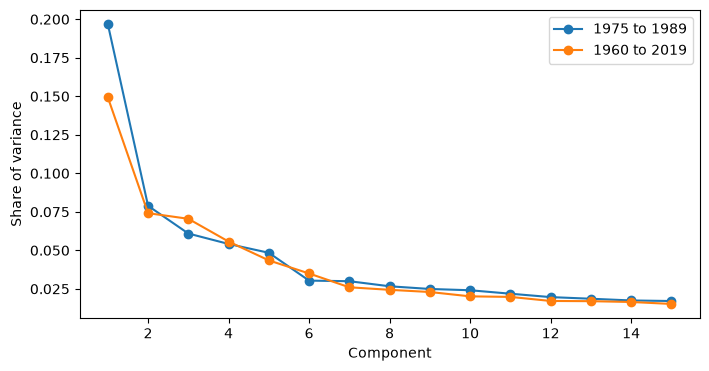

r (1975-1989): 5 | r (1960-2019): 7


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def eigvals(D):
    Z = (D - D.mean()) / D.std()
    return np.linalg.eigvalsh(np.cov(Z, rowvar=False))[::-1]

def ic_p2(D, kmax=15):
    T, N = D.shape
    ev = eigvals(D)
    ic = [np.log(ev[k:].sum() / N) + k * (N + T) / (N * T) * np.log(min(N, T))
          for k in range(kmax + 1)]
    return int(np.argmin(ic))

full = df.loc["1960":"2019"]
full = full.drop(columns=full.columns[full.isna().any()])

fig, ax = plt.subplots(figsize=(8, 4))
for label, D in [("1975 to 1989", desc), ("1960 to 2019", full)]:
    ev = eigvals(D)
    ax.plot(range(1, 16), ev[:15] / ev.sum(), marker="o", label=label)
ax.set_xlabel("Component")
ax.set_ylabel("Share of variance")
ax.legend()
plt.show()

print("r (1975-1989):", ic_p2(desc), "| r (1960-2019):", ic_p2(full))

- Clear elbow after the first component: factor 1 explains 19.7% of the variance in 1975 to 1989,
  2.5 times the second (7.9%), after which the curve flattens.
- The first factor is stronger than in 1960 to 2019 (14.9%), so there's more common movement
  in my period than on average.
- IC_p2 picks r = 5 for 1975 to 1989 and r = 7 for 1960 to 2019. Fewer factors with a shorter
  sample is expected, since T = 180 is small relative to N = 124.
- Splitting at 1984, factor 1's share falls from 22.4% to 13.4% and IC_p2 drops from 5 to 3,
so the factor structure weakens in the calm half (T = 72 there, so treat this loosely).

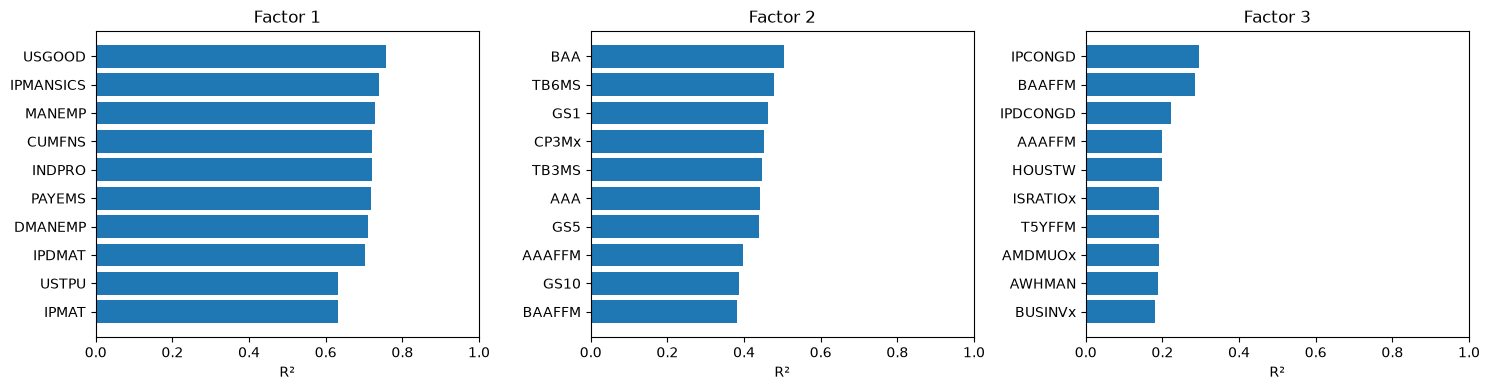

In [9]:
Z = (desc - desc.mean()) / desc.std()
eigval, eigvec = np.linalg.eigh(np.cov(Z, rowvar=False))
order = np.argsort(eigval)[::-1]
F = Z.values @ eigvec[:, order[:3]]          # first 3 factors, T x 3

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, ax in enumerate(axes):
    r2 = Z.apply(lambda s: np.corrcoef(F[:, k], s)[0, 1] ** 2)
    top = r2.sort_values().tail(10)
    ax.barh(top.index, top.values)
    ax.set_title(f"Factor {k + 1}")
    ax.set_xlabel("R²")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

- F1 is real activity: goods employment, manufacturing IP, capacity utilisation, INDPRO and
  payrolls all have R² around 0.7.
- F2 is interest rates: bond yields, T-bills and commercial paper, R² around 0.4 to 0.5.
- F3 is weak and mixed (max R² about 0.3), so I don't give it a label.

## Forecasting

Target: INDPRO growth, forecast h = 1 and h = 12 months ahead (for h = 12, average monthly growth
over the next 12 months). Benchmark: AR with BIC choosing 0 to 6 lags. Diffusion index model: the
same AR plus the first r = 1, 2, 3 PCA factors. Expanding window from 1960: at each forecast origin
the factors and both regressions are re-estimated using only data available at that date.
Forecasts are evaluated for target dates January 1975 to December 1989.

In [14]:
TARGET = "INDPRO"
HORIZONS = [1, 12]
R_LIST = [1, 2, 3]
PMAX = 6
EVAL_START, EVAL_END = "1975-01-01", "1989-12-01"

ip = train[TARGET]

def h_ahead(h):
    """Average growth over months t+1..t+h, stored at origin t."""
    return ip.rolling(h).sum().shift(-h) / h

def factors(X):
    """First max(R_LIST) PCA factors, standardised with data up to the origin only."""
    Z = (X - X.mean()) / X.std()
    U, S, Vt = np.linalg.svd(Z.values, full_matrices=False)
    return pd.DataFrame(U[:, :max(R_LIST)] * np.sqrt(len(Z)), index=X.index)

lags = pd.concat({j: ip.shift(j) for j in range(PMAX)}, axis=1)

rows = []
for h in HORIZONS:
    yh = h_ahead(h)
    for target_date in pd.date_range(EVAL_START, EVAL_END, freq="MS"):
        t = target_date - pd.DateOffset(months=h)          # forecast origin
        F = factors(train.loc[:t])                          # re-estimated every origin
        s = yh.loc[:t - pd.DateOffset(months=h)].index[PMAX:]   # targets already known at t
        y = yh.loc[s].values

        # AR lag order by BIC
        best = None
        for p in range(PMAX + 1):
            R = np.column_stack([np.ones(len(s))] + [lags.loc[s, j] for j in range(p)])
            e = y - R @ np.linalg.lstsq(R, y, rcond=None)[0]
            bic = np.log(e @ e / len(e)) + R.shape[1] * np.log(len(e)) / len(e)
            if best is None or bic < best[0]:
                best = (bic, p)
        p = best[1]

        actual = yh.loc[t]
        row = {"h": h, "target_date": target_date, "p": p}
        for r in [0] + R_LIST:                              # r = 0 is the AR benchmark
            regs = np.column_stack([np.ones(len(s))] + [lags.loc[s, j] for j in range(p)]
                                   + [F.loc[s, k] for k in range(r)])
            x_now = np.array([1] + [lags.loc[t, j] for j in range(p)]
                             + [F.loc[t, k] for k in range(r)])
            b = np.linalg.lstsq(regs, y, rcond=None)[0]
            row["ar" if r == 0 else f"di_r{r}"] = actual - x_now @ b
        rows.append(row)

errors = pd.DataFrame(rows)
errors.to_csv(ROOT / "periods" / PERIOD / "results" / "forecast_errors.csv", index=False)
print(errors.groupby("h").size())   # 180 forecasts per horizon

h
1     180
12    180
dtype: int64


## Evaluation

In [15]:
def mse_ratios(e):
    ar = (e["ar"] ** 2).mean()
    return {f"r={r}": (e[f"di_r{r}"] ** 2).mean() / ar for r in R_LIST}

splits = {"1975-1989": ("1975", "1989"), "1975-1983": ("1975", "1983"), "1984-1989": ("1984", "1989")}

table = {}
for h in HORIZONS:
    e = errors[errors.h == h].set_index("target_date")
    for name, (a, b) in splits.items():
        table[(f"h={h}", name)] = mse_ratios(e.loc[a:b])

table = pd.DataFrame(table).T.round(2)
table.to_csv(ROOT / "periods" / PERIOD / "results" / "mse_ratios.csv")
table

r=1   r=2   r=3
h=1  1975-1989  0.86  0.87  0.82
     1975-1983  0.81  0.81  0.77
     1984-1989  1.07  1.11  1.07
h=12 1975-1989  0.91  0.64  0.55
     1975-1983  0.87  0.48  0.43
     1984-1989  1.22  1.86  1.49

- Over 1975 to 1989 every ratio is below 1, so factors beat the AR at both horizons;
  r = 3 is best (0.82 at h = 1, 0.55 at h = 12).
- The gain comes entirely from 1975 to 1983 (0.77 and 0.43 for r = 3). In 1984 to 1989 every
  ratio is above 1 (1.07 to 1.86), so the AR wins.
- Gains are larger at h = 12, but mostly from r = 2 and 3; with one factor the h = 12 gain is small (0.91).

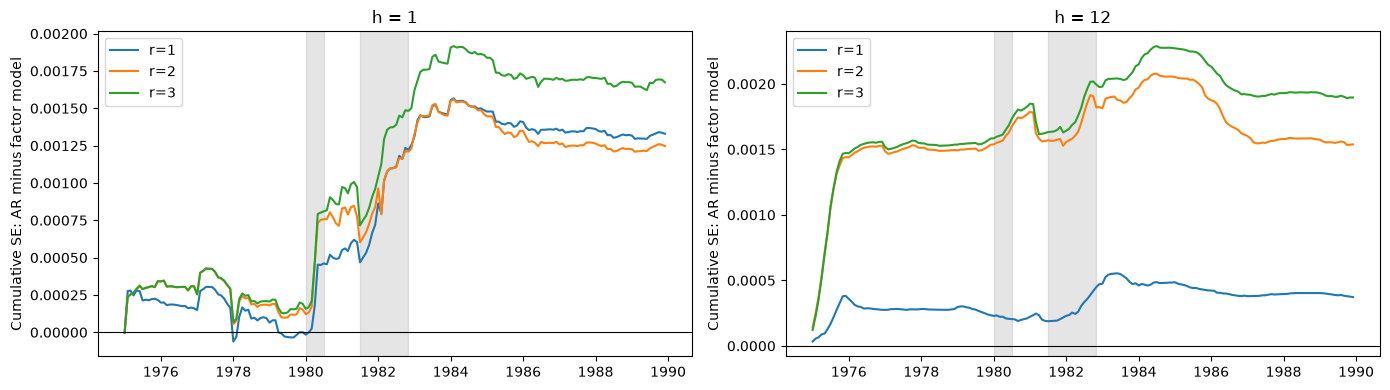

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, h in zip(axes, HORIZONS):
    e = errors[errors.h == h].set_index("target_date")
    for r in R_LIST:
        ax.plot(e.index, (e["ar"] ** 2 - e[f"di_r{r}"] ** 2).cumsum(), label=f"r={r}")
    for a, b in [("1980-01", "1980-07"), ("1981-07", "1982-11")]:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"h = {h}")
    ax.set_ylabel("Cumulative SE: AR minus factor model")
    ax.legend()
plt.tight_layout()
plt.show()

- h = 1: gains are concentrated in the 1980 and 1981 to 82 recessions; the cumulative line
  peaks in early 1984 and declines afterwards.
- h = 12: most of the gain comes in 1975 (targets covering the end of the 1973 to 75 recession),
  so the h = 12 result relies heavily on one episode.
- Adding F2 (rates) is what separates r = 2, 3 from r = 1 at h = 12.
- After 1985 the factor models lose ground at both horizons.

## Results
- **Structure:** clear factor structure in 1975 to 1989 (IC_p2 picks r = 5); F1 is real activity,
  F2 is interest rates. The structure weakens after 1984.
- **Forecasts:** factors beat the AR for INDPRO at h = 1 and h = 12, but only in 1975 to 1983;
  from 1984 the AR wins.
- **Takeaway:** factor models help in turbulent periods and not in calm ones. At h = 12 the gain
  relies on the rates factor and heavily on 1975.## Results